## Imports and Setup

In [1]:
%pip install -q rapidfuzz

In [2]:
import copy
import time
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
import re

from rapidfuzz import process, fuzz

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.metrics.pairwise import PAIRWISE_KERNEL_FUNCTIONS
from sklearn.model_selection import ParameterSampler

from xgboost import XGBClassifier

np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Dataset Loading

**Outcome:** at least **3 distinct households** each watch **at least one-third** of the title runtime **within 6 months** after acquisition. Only titles with a complete eligible six-month observation window are labelled for supervised learning. Titles with incomplete follow-up remain unlabelled.

In [3]:
# Load data

viewing = pd.read_csv("https://docs.google.com/spreadsheets/d/e/2PACX-1vR47OdFiWY13aDvTZN4QIbiMODrZlyDQ29q6Jgn2BrpofN1ZjmbJ4X95U8RrmssMd5PVD8AVvpjKo95/pub?gid=737932283&single=true&output=csv")
catalogue = pd.read_csv( "https://docs.google.com/spreadsheets/d/e/2PACX-1vTp01l3Uiqy4c_B9AT1q-cWpwDa-vphrvDeT0etTu6Xe4XHBEFoJjJzj9IUZL-V2K7BH9_LyyU5rJHJ/pub?gid=1759543568&single=true&output=csv")
tmdb = pd.read_csv("https://docs.google.com/spreadsheets/d/e/2PACX-1vTREHT79TLNL9A_G8mbWvessC2JcmOLgfiPRPty_i1yKuo-Rf5191D2XUREM4Q7x5R7NncdNzGUdxUF/pub?gid=386996102&single=true&output=csv")

# Check for missing values
print("\nMissing values:")
display(viewing.isna().sum().to_frame("Viewing"))
display(catalogue.isna().sum().to_frame("Catalogue"))
display(tmdb.isna().sum().to_frame("TMDB"))


Missing values:


,Viewing
household_id,0
session_id,0
event_timestamp,0
title_id,8853
event_type,0
watch_duration,9157
title_runtime,0


,Catalogue
title_id,0
title_name,0
acquisition_date,0
content_type,0
licensing_cost_usd,0
license_expiry_date,0
release_year,0
new_title,0


,TMDB
tmdb_id,0
stadio_title_id,0
genres,0
lead_actors,0
user_score,0
original_language,0
network,0


## Dataset Preprocessing

In [4]:
viewing.info()
catalogue.info()
tmdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45305 entries, 0 to 45304
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   household_id     45305 non-null  object 
 1   session_id       45305 non-null  object 
 2   event_timestamp  45305 non-null  int64  
 3   title_id         36452 non-null  object 
 4   event_type       45305 non-null  object 
 5   watch_duration   36148 non-null  float64
 6   title_runtime    45305 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 2.4+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1140 entries, 0 to 1139
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   title_id             1140 non-null   object 
 1   title_name           1140 non-null   object 
 2   acquisition_date     1140 non-null   object 
 3   content_type         1140 non-null   object 
 4   licen

In [5]:
from sklearn.metrics.pairwise import PAIRWISE_KERNEL_FUNCTIONS
# make primary key the same by stripping any additional characters and lowering the key

viewing['title_id'] = viewing['title_id'].str.strip().str.lower()
catalogue['title_id'] = catalogue['title_id'].str.strip().str.lower()
tmdb["stadio_title_id"] = tmdb["stadio_title_id"].str.strip().str.lower()

# transforming data types
viewing["event_type"] = viewing["event_type"].str.strip().str.lower()
viewing["event_date"] = pd.to_datetime(viewing["event_timestamp"],unit="s",utc=True).dt.tz_localize(None)
catalogue["acquisition_date"] = pd.to_datetime(catalogue["acquisition_date"],errors="coerce")
catalogue["license_expiry_date"] = pd.to_datetime(catalogue["license_expiry_date"],errors="coerce")

print("Datatype after conversion")
print("Viewing events:")
viewing.info()
print("####################")
print("Catalogue titles:")
catalogue.info()
print("####################")
print("Metadata records:")
tmdb.info()

Datatype after conversion
Viewing events:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45305 entries, 0 to 45304
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   household_id     45305 non-null  object        
 1   session_id       45305 non-null  object        
 2   event_timestamp  45305 non-null  int64         
 3   title_id         36452 non-null  object        
 4   event_type       45305 non-null  object        
 5   watch_duration   36148 non-null  float64       
 6   title_runtime    45305 non-null  int64         
 7   event_date       45305 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(2), object(4)
memory usage: 2.8+ MB
####################
Catalogue titles:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1140 entries, 0 to 1139
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               -----------

In [6]:
# removing duplicates

viewing = viewing.drop_duplicates()
catalogue = catalogue.drop_duplicates("title_id")
tmdb = tmdb.drop_duplicates("stadio_title_id")

print("Dataframe lengths after dedupe")
print("Viewing events:", len(viewing))
print("Catalogue titles:", len(catalogue))
print("Metadata records:", len(tmdb))

Dataframe lengths after dedupe
Viewing events: 45304
Catalogue titles: 1140
Metadata records: 1076


In [7]:
# Six-month engagement observation window.

OBSERVATION_MONTHS = 6

log_start = pd.Timestamp("2023-09-01")
log_end = pd.Timestamp("2026-09-01")

catalogue["outcome_end"] = (
    catalogue["acquisition_date"]
    + pd.DateOffset(months=OBSERVATION_MONTHS)
)

cohort = catalogue[
    (catalogue["acquisition_date"] >= log_start)
    & (catalogue["outcome_end"] <= log_end)
    & (
        catalogue["license_expiry_date"]
        + pd.Timedelta(days=1)
        >= catalogue["outcome_end"]
    )
].copy()

print("Eligible titles:", len(cohort))

Eligible titles: 465


In [8]:
# Keep only events containing valid viewing durations.

plays = viewing[viewing["event_type"].isin(["play", "pause"])& viewing["title_id"].notna()& viewing["watch_duration"].notna()& (viewing["watch_duration"] >= 0)& (viewing["title_runtime"] > 0)].copy()
plays = plays.merge(cohort[["title_id","acquisition_date","outcome_end"]],on="title_id",how="inner")
plays = plays[(plays["event_date"] >= plays["acquisition_date"])& (plays["event_date"] < plays["outcome_end"])]


# The duration is cumulative WITHIN a session.
# Keep the maximum instead of summing Play/Pause events.

sessions = (plays.groupby(["title_id", "household_id", "session_id"],as_index=False).agg(session_watch_seconds=("watch_duration", "max"),title_runtime=("title_runtime", "max")))


# Sum across the household's separate viewing sessions.

households = (sessions.groupby(["title_id", "household_id"],as_index=False).agg(total_watch_seconds=("session_watch_seconds", "sum"),title_runtime=("title_runtime", "max")))

households["qualifies"] = (households["total_watch_seconds"]>= households["title_runtime"] / 3)


# Count qualifying households for each title.

qualifiers = (households.groupby("title_id")["qualifies"].sum().rename("qualifying_households").reset_index())

cohort = cohort.merge(qualifiers,on="title_id",how="left")

cohort["qualifying_households"] = (cohort["qualifying_households"].fillna(0).astype(int))

cohort["target"] = (cohort["qualifying_households"] >= 3).astype(int)

print("Eligible titles:", len(cohort))
print("Successful titles:", cohort["target"].sum())
print("Positive rate:", round(cohort["target"].mean(), 4))

display(cohort["target"].value_counts().sort_index().rename("titles").to_frame())

Eligible titles: 465
Successful titles: 121
Positive rate: 0.2602


,titles
target,
0,344
1,121


In [9]:
# Split by acquisition date, keeping titles from the same acquisition date together.

dates = sorted(cohort["acquisition_date"].unique())
cutoffs = [dates[int(len(dates) * proportion)]for proportion in (0.60, 0.75, 0.85)]
cohort["role"] = np.select([cohort["acquisition_date"] < cutoffs[0],cohort["acquisition_date"] < cutoffs[1],cohort["acquisition_date"] < cutoffs[2]],["train","tune","calibration"],default="test")
display(cohort.groupby("role")["target"].agg(titles="count",positives="sum",positive_rate="mean"))
display(cohort.groupby("role")["acquisition_date"].agg(["min", "max"]))

,titles,positives,positive_rate
role,,,
calibration,51,14,0.274510
test,68,18,0.264706
train,273,73,0.267399
tune,73,16,0.219178


,min,max
role,,
calibration,2025-07-27,2025-10-27
test,2025-10-30,2026-02-28
train,2023-09-05,2025-02-15
tune,2025-02-18,2025-07-18


In [10]:
# Prepare the metadata table

tmdb = tmdb.rename(columns={"stadio_title_id": "title_id"})
titles = catalogue.merge(tmdb,on="title_id",how="left",validate="one_to_one")
titles = titles.merge(cohort[["title_id", "target", "role"]],on="title_id",how="left",validate="one_to_one")
titles["role"] = titles["role"].fillna("unlabelled")
titles["target"] = titles["target"].fillna(-1).astype(int)
titles = titles.sort_values("title_id").reset_index(drop=True)
titles["node_id"] = np.arange(len(titles))


# Metadata features available when evaluating a title.

titles["title_age_at_acquisition"] = (titles["acquisition_date"].dt.year- titles["release_year"]).clip(lower=0)
titles["release_year_missing"] = (titles["release_year"].isna().astype(int))
titles["genre_list"] = (titles["genres"].fillna("").map(lambda value: sorted({genre.strip().lower()for genre in value.split(",")if genre.strip()})))
titles["genre_count"] = titles["genre_list"].map(len)
titles["lead_actor_count"] = (titles["lead_actors"].fillna("").map(lambda value: len([actor for actor in value.split(",")if actor.strip()])))
titles["tmdb_available_flag"] = (titles["tmdb_id"].notna().astype(int))
titles["new_title_flag"] = (titles["new_title"].astype(int))
titles["release_decade"] = (titles["release_year"].fillna(titles.loc[titles["role"] == "train","release_year"].median())// 10 * 10).astype(int)

for column in ["content_type","original_language","network"]:
    titles[column] = (titles[column].fillna("unknown").astype(str).str.strip().str.lower().replace("", "unknown"))

In [11]:
def parse_actors(value):
    if pd.isna(value):
        return []

    return sorted({
        re.sub(r"\s+", " ", actor.strip()).casefold()
        for actor in str(value).split(",")
        if actor.strip()
    })


titles["actor_list"] = titles["lead_actors"].map(
    parse_actors
)


# Select actors using training titles only.

actor_counts = Counter(actor
for actors in titles.loc[
        titles["role"] == "train",
        "actor_list"
    ]
    for actor in actors
)

top_actors = [
    actor
    for actor, count in actor_counts.most_common(20)
]


# Multi-hot encoding: a title can contain multiple actors.

actor_flags = pd.DataFrame(
    {
        "actor_" + re.sub(
            r"[^a-z0-9]+", "_", actor
        ).strip("_"): titles["actor_list"].map(
            lambda actors, name=actor: float(name in actors)
        )
        for actor in top_actors
    },
    index=titles.index
)

### Historical Viewing Feature

As I was building the notebook I realised that the model needed more feature. This cell build historical view features based off of similar titles for each title before it was aquired.

In [12]:
#  Reconstruct historical viewing sessions.
#
# Use the FULL viewing dataset, rather than 'plays' or'cohort', which were restricted for target construction.

history_events = viewing.loc[
    viewing["event_type"].isin(["play", "pause"])
    & viewing["title_id"].notna()
    & viewing["household_id"].notna()
    & viewing["session_id"].notna()
].copy()

for col in ["watch_duration", "title_runtime"]:
    history_events[col] = pd.to_numeric(
        history_events[col],
        errors="coerce"
    )

history_events = history_events.loc[
    history_events["watch_duration"].notna()
    & (history_events["watch_duration"] >= 0)
    & (history_events["title_runtime"] > 0)
]


# Attach historical title information.

history_events = history_events.merge(
    titles[
        [
            "title_id",
            "acquisition_date",
            "license_expiry_date",
            "genre_list",
            "content_type"
        ]
    ],
    on="title_id",
    how="inner",
    validate="many_to_one"
)


# Only retain viewing activity inside the licensing period.

history_events = history_events.loc[
    (
        history_events["event_date"]
        >= history_events["acquisition_date"]
    )
    & (
        history_events["event_date"]
        < (
            history_events["license_expiry_date"]
            + pd.Timedelta(days=1)
        )
    )
].copy()


# Watch duration is cumulative within a session. Retain the maximum rather than summing Play/Pause events.

historical_sessions = (
    history_events
    .groupby(
        ["title_id", "household_id", "session_id"],
        as_index=False
    )
    .agg(
        session_end=("event_date", "max"),
        watch_seconds=("watch_duration", "max"),
        runtime_seconds=("title_runtime", "max"),
        genre_list=("genre_list", "first"),
        content_type=("content_type", "first")
    )
)


# Calculate session-level engagement. Cap viewing fraction at 100% for abnormal durations.

historical_sessions["watch_fraction"] = (
    historical_sessions["watch_seconds"]
    / historical_sessions["runtime_seconds"]
).clip(0, 1)

historical_sessions["completed_session"] = (
    historical_sessions["watch_fraction"] >= (1/3)
).astype(float)



# Create efficient historical lookup tables.

def build_lookup(df, key_col):

    result = {}

    for key, block in df.groupby(key_col, sort=False):

        block = block.sort_values("session_end")

        result[key] = {
            "time": block["session_end"].to_numpy(
                dtype="datetime64[ns]"
            ),

            "completed_cumsum": np.r_[
                0.,
                block["completed_session"]
                .to_numpy()
                .cumsum()
            ],

            "watch_cumsum": np.r_[
                0.,
                block["watch_fraction"]
                .to_numpy()
                .cumsum()
            ]
        }

    return result


# Overall platform history.

all_history = build_lookup(
    historical_sessions.assign(history_key="all"),
    "history_key"
)


# Viewing history by genre.

genre_history = build_lookup(
    historical_sessions
    .explode("genre_list")
    .dropna(subset=["genre_list"])
    .rename(columns={"genre_list": "history_key"}),
    "history_key"
)


# Viewing history by content type.

type_history = build_lookup(
    historical_sessions.rename(
        columns={"content_type": "history_key"}
    ),
    "history_key"
)



# Point-in-time feature calculations.

def prior_stats(
    lookup,
    key,
    asof,
    start_days,
    end_days=0
):

    """
    Returns:
        1. Session count
        2. Completed session count
        3. Sum of session watch fractions

    Uses only the period:
        [asof - start_days, asof - end_days)

    The acquisition date itself is excluded.
    """

    entry = lookup.get(key)

    if entry is None or pd.isna(asof):
        return np.zeros(3, dtype=float)

    dates = entry["time"]

    lo = np.searchsorted(
        dates,
        np.datetime64(
            asof - pd.Timedelta(days=start_days)
        ),
        side="left"
    )

    hi = np.searchsorted(
        dates,
        np.datetime64(
            asof - pd.Timedelta(days=end_days)
        ),
        side="left"
    )

    return np.array([
        hi - lo,

        (
            entry["completed_cumsum"][hi]
            - entry["completed_cumsum"][lo]
        ),

        (
            entry["watch_cumsum"][hi]
            - entry["watch_cumsum"][lo]
        )
    ], dtype=float)


# Account for partial history near the beginning of the logs. For example, September 2023 does not have a full 365-day history available.

history_start = viewing["event_date"].min().floor("D")


def available_days(asof, start_days, end_days=0):

    start = max(
        asof - pd.Timedelta(days=start_days),
        history_start
    )

    end = asof - pd.Timedelta(days=end_days)

    return max(
        (end - start).total_seconds() / 86400,
        0.0
    )


# Generate historical features for every catalogue title.


rows = []

# Smooth sparse genre/content-type rates towards the historical platform average.
SMOOTHING = 20.0

for row in titles[
    [
        "title_id",
        "acquisition_date",
        "genre_list",
        "content_type"
    ]
].itertuples(index=False):

    t = row.acquisition_date

    # Overall viewing history.

    global90 = prior_stats(
        all_history, "all", t, 90
    )

    global365 = prior_stats(
        all_history, "all", t, 365
    )

    overall_completion = (
        (global365[1] + 1)
        / (global365[0] + 2)
    )

    overall_fraction = (
        global365[2] / global365[0]
        if global365[0] > 0
        else 0.5
    )


    # Genre viewing history.

    g90 = [
        prior_stats(genre_history, g, t, 90)
        for g in row.genre_list
    ]

    gprev = [
        prior_stats(genre_history, g, t, 180, 90)
        for g in row.genre_list
    ]

    g365 = [
        prior_stats(genre_history, g, t, 365)
        for g in row.genre_list
    ]

    recent = (
        np.mean(g90, axis=0)
        if g90 else np.zeros(3)
    )

    previous = (
        np.mean(gprev, axis=0)
        if gprev else np.zeros(3)
    )

    genre365 = (
        np.mean(g365, axis=0)
        if g365 else np.zeros(3)
    )


    # Same-content-type history.

    content365 = prior_stats(
        type_history,
        row.content_type,
        t,
        365
    )


    # Correct for incomplete historical windows.

    days90 = available_days(t, 90)

    days_prev = available_days(t, 180, 90)

    days365 = available_days(t, 365)


    recent_rate = (
        recent[0] / max(days90, 1)
    )

    previous_rate = (
        previous[0] / max(days_prev, 1)
    )


    # Compare recent and preceding 90-day viewing rates. Neutral trend where there is insufficient history.

    trend = (
        (recent_rate + 0.05)
        / (previous_rate + 0.05)

        if days90 >= 30 and days_prev >= 30

        else 1.0
    )


    rows.append({

        "title_id": row.title_id,

        "hist_global_sessions_per_day_90d":
            global90[0] / max(days90, 1),

        "hist_genre_sessions_per_day_90d":
            recent_rate,

        "hist_genre_sessions_per_day_365d":
            genre365[0] / max(days365, 1),

        "hist_genre_session_support_365d":
            genre365[0],

        "hist_genre_completion_rate_365d":
            (
                genre365[1]
                + SMOOTHING * overall_completion
            )
            / (genre365[0] + SMOOTHING),

        "hist_genre_watch_fraction_365d":
            (
                genre365[2]
                + SMOOTHING * overall_fraction
            )
            / (genre365[0] + SMOOTHING),

        "hist_genre_trend_90d":
            trend,

        "hist_genre_share_90d":
            recent[0] / max(global90[0], 1),

        "hist_type_sessions_per_day_365d":
            content365[0] / max(days365, 1),

        "hist_type_completion_rate_365d":
            (
                content365[1]
                + SMOOTHING * overall_completion
            )
            / (content365[0] + SMOOTHING)

    })



# Merge features into the existing modelling table.

historical_features = pd.DataFrame(rows)

titles = titles.merge(
    historical_features,
    on="title_id",
    how="left",
    validate="one_to_one"
)

historical_feature_columns = [
    c
    for c in historical_features.columns
    if c != "title_id"
]


# Check that the new predictors contain valid numeric values.

assert (
    titles[historical_feature_columns]
    .notna()
    .all()
    .all()
)

assert np.isfinite(
    titles[historical_feature_columns].to_numpy()
).all()


print("Historical sessions:", len(historical_sessions))
print("New features:", len(historical_feature_columns))

display(
    titles[historical_feature_columns]
    .describe()
    .T
    .round(3)
)

Historical sessions: 6990
New features: 10


,count,mean,std,min,25%,50%,75%,max
hist_global_sessions_per_day_90d,1140.0,3.091,3.189,0.000,0.0,0.0,6.478,7.311
hist_genre_sessions_per_day_90d,1140.0,0.349,0.400,0.000,0.0,0.0,0.722,1.378
hist_genre_sessions_per_day_365d,1140.0,0.341,0.389,0.000,0.0,0.0,0.705,1.200
hist_genre_session_support_365d,1140.0,106.833,133.658,0.000,0.0,0.0,228.958,438.000
hist_genre_completion_rate_365d,1140.0,0.641,0.145,0.500,0.5,0.5,0.788,0.886
hist_genre_watch_fraction_365d,1140.0,0.563,0.066,0.500,0.5,0.5,0.628,0.787
hist_genre_trend_90d,1140.0,1.012,0.110,0.657,1.0,1.0,1.000,2.015
hist_genre_share_90d,1140.0,0.055,0.063,0.000,0.0,0.0,0.114,0.222
hist_type_sessions_per_day_365d,1140.0,0.894,1.025,0.000,0.0,0.0,2.048,2.745
hist_type_completion_rate_365d,1140.0,0.639,0.143,0.500,0.5,0.5,0.781,0.885


In [13]:
# Attach actors to historical viewing sessions.

actor_session_history = (
    historical_sessions[
        [
            "title_id",
            "session_end",
            "completed_session",
            "watch_fraction"
        ]
    ]
    .merge(
        titles[["title_id", "actor_list"]],
        on="title_id",
        how="left",
        validate="many_to_one"
    )
    .explode("actor_list")
    .dropna(subset=["actor_list"])
    .rename(
        columns={"actor_list": "history_key"}
    )
)

actor_history = build_lookup(
    actor_session_history,
    "history_key"
)


actor_rows = []

for row in titles[
    ["title_id", "acquisition_date", "actor_list"]
].itertuples(index=False):

    actor_stats = [
        prior_stats(
            actor_history,
            actor,
            row.acquisition_date,
            365
        )
        for actor in row.actor_list
    ]

    average_actor = (
        np.mean(actor_stats, axis=0)
        if actor_stats
        else np.zeros(3)
    )

    global_stats = prior_stats(
        all_history,
        "all",
        row.acquisition_date,
        365
    )

    global_completion = (
        (global_stats[1] + 1)
        / (global_stats[0] + 2)
    )

    smoothing = 20.0

    actor_rows.append({
        "title_id": row.title_id,

        "hist_actor_sessions_per_day_365d":
            average_actor[0]
            / max(available_days(row.acquisition_date, 365), 1),

        "hist_actor_completion_rate_365d":
            (
                average_actor[1]
                + smoothing * global_completion
            )
            / (average_actor[0] + smoothing),

        "hist_actor_session_support_365d":
            average_actor[0]
    })


actor_history_features = pd.DataFrame(actor_rows)

titles = titles.merge(
    actor_history_features,
    on="title_id",
    how="left",
    validate="one_to_one"
)

actor_history_feature_columns = [
    c for c in actor_history_features.columns
    if c != "title_id"
]

### Integrate search data to predict demand

In [14]:
search = pd.read_csv("https://docs.google.com/spreadsheets/d/e/2PACX-1vSUrURjf8tkeH8bpCNauhmu2PSOyxnjp3OHhHp9Zsd-YYhRASUknPJgaT9es1ZqQCyxxEBt0vdeo5Co/pub?gid=195541149&single=true&output=csv").drop_duplicates()

search["search_at"] = pd.to_datetime(
    search["search_timestamp"],
    unit="s",
    utc=True
).dt.tz_localize(None)


def normalise_search_text(value):
    text = str(value).casefold()
    text = re.sub(r"[^a-z0-9]+", " ", text)
    return " ".join(text.split())


# Strip common search suffixes, but only after checking whether the original query matches exactly.

suffix_pattern = re.compile(
    r"\s+(?:trailer|cast|full\s+movie|full\s+moive|"
    r"episode\s*\d+|season\s*\d+)$"
)


def strip_search_suffixes(query):
    while True:
        updated = suffix_pattern.sub("", query).strip()

        if updated == query:
            return query

        query = updated


titles["title_search_key"] = (
    titles["title_name"].map(normalise_search_text)
)

title_lookup = dict(
    zip(
        titles["title_search_key"],
        titles["title_id"]
    )
)

candidate_names = list(title_lookup)


def match_search_query(query):

    if not query:
        return None, "unmatched", 0.0

    # First: exact match without modifying the query.

    if query in title_lookup:
        return title_lookup[query], "exact", 100.0

    # Second: remove common search qualifiers.

    cleaned = strip_search_suffixes(query)

    if cleaned in title_lookup:
        return title_lookup[cleaned], "suffix_exact", 100.0

    # Third: conservative fuzzy matching.

    if len(cleaned) < 7 or len(cleaned.split()) < 2:
        return None, "unmatched", 0.0

    candidates = process.extract(
        cleaned,
        candidate_names,
        scorer=fuzz.ratio,
        limit=2
    )

    if not candidates:
        return None, "unmatched", 0.0

    best_name, best_score, _ = candidates[0]

    second_score = (
        candidates[1][1]
        if len(candidates) > 1
        else 0
    )

    # Require a strong, unambiguous match.

    if (
        best_score >= 92
        and best_score - second_score >= 8
        and abs(len(cleaned) - len(best_name)) <= 3
    ):
        return (
            title_lookup[best_name],
            "fuzzy",
            float(best_score)
        )

    return None, "unmatched", float(best_score)


search["query_key"] = (
    search["search_term"].map(normalise_search_text)
)

match_cache = {
    query: match_search_query(query)
    for query in search["query_key"].unique()
}

search[
    ["matched_title_id", "match_method", "match_score"]
] = pd.DataFrame(
    search["query_key"].map(match_cache).tolist(),
    index=search.index
)



In [15]:
# Attach acquisition dates to successfully matched searches.

matched_searches = (
    search.loc[
        search["matched_title_id"].notna()
    ]
    .merge(
        titles[["title_id", "acquisition_date"]],
        left_on="matched_title_id",
        right_on="title_id",
        how="inner",
        validate="many_to_one"
    )
)

matched_searches["days_before_acquisition"] = (
    (
        matched_searches["acquisition_date"]
        - matched_searches["search_at"]
    ).dt.total_seconds() / 86400
)


# Exclude searches on or after acquisition. Retain only the prior 365 days.

prior_searches = matched_searches.loc[
    (matched_searches["days_before_acquisition"] > 0)
    & (matched_searches["days_before_acquisition"] <= 365)
].copy()

prior_searches["within_90d"] = (
    prior_searches["days_before_acquisition"] <= 90
).astype(int)


# Aggregate title-specific search counts.

search_counts = (
    prior_searches
    .groupby("matched_title_id")
    .agg(
        search_count_365d=("session_id", "size"),
        search_count_90d=("within_90d", "sum")
    )
)

titles = titles.join(
    search_counts,
    on="title_id"
)

for column in [
    "search_count_90d",
    "search_count_365d"
]:
    titles[column] = (
        titles[column]
        .fillna(0)
        .astype(float)
    )


# Calculate total platform searches within each time window. This provides a denominator for relative demand.

all_search_times = np.sort(
    search["search_at"].to_numpy(
        dtype="datetime64[ns]"
    )
)

acquisition_times = (
    titles["acquisition_date"]
    .to_numpy(dtype="datetime64[ns]")
)

search_history_start = (
    search["search_at"].min().floor("D")
)


for days in [90, 365]:

    total_searches = (
        np.searchsorted(
            all_search_times,
            acquisition_times,
            side="left"
        )
        -
        np.searchsorted(
            all_search_times,
            acquisition_times - np.timedelta64(days, "D"),
            side="left"
        )
    )

    coverage_days = np.array([
        max(
            0.0,
            (
                acquisition_date
                - max(
                    acquisition_date - pd.Timedelta(days=days),
                    search_history_start
                )
            ).total_seconds() / 86400
        )
        for acquisition_date in titles["acquisition_date"]
    ])

    titles[f"search_coverage_days_{days}d"] = coverage_days

    title_counts = titles[
        f"search_count_{days}d"
    ].to_numpy()


    # Searches per 30 days, where at least 30 days
    # of historical data are available.

    titles[f"search_rate_per30d_{days}d"] = np.where(
        coverage_days >= 30,
        title_counts / np.maximum(coverage_days, 1) * 30,
        np.nan
    )


    # Candidate title's share of platform searches.

    titles[f"search_share_{days}d"] = np.where(
        total_searches >= 30,
        title_counts / np.maximum(total_searches, 1),
        np.nan
    )


search_feature_columns = [
    "search_count_90d",
    "search_count_365d",
    "search_rate_per30d_90d",
    "search_rate_per30d_365d",
    "search_share_90d",
    "search_share_365d",
    "search_coverage_days_90d",
    "search_coverage_days_365d"
]

## Exploratory Data Analysis of Features

In [16]:
eda = cohort.copy()

eda["content_type"] = (
    eda["content_type"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .str.title()
)

def add_bar_labels(ax, bars, suffix=""):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:,.1f}{suffix}" if suffix else f"{height:,.0f}",
            (bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=11
        )

Text(0.5, -0.16, 'Eligibility requires complete six-month follow-up and valid licensing.')

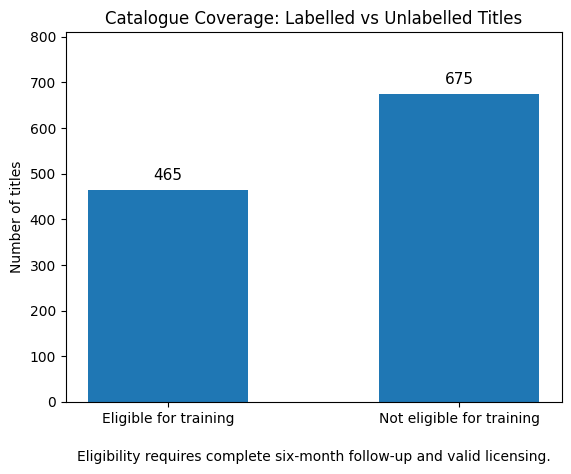

In [17]:
# Traning elegibility

eligible = len(eda)
not_eligible = len(catalogue) - eligible

fig, ax = plt.subplots()

bars = ax.bar(
    ["Eligible for training", "Not eligible for training"],
    [eligible, not_eligible],
    width=0.55
)

add_bar_labels(ax, bars)

ax.set_title("Catalogue Coverage: Labelled vs Unlabelled Titles")
ax.set_ylabel("Number of titles")
ax.set_ylim(0, max(eligible, not_eligible) * 1.2)

ax.text(
    0.5, -0.16,
    "Eligibility requires complete six-month follow-up and valid licensing.",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

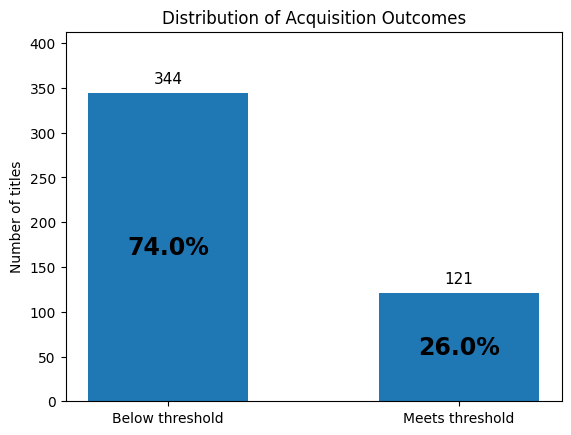

In [18]:
# Target class distribution

counts = eda["target"].value_counts().reindex(
    [0, 1], fill_value=0
)

fig, ax = plt.subplots()

bars = ax.bar(
    ["Below threshold", "Meets threshold"],
    counts.values,
    width=0.55
)

add_bar_labels(ax, bars)

ax.set_title("Distribution of Acquisition Outcomes")
ax.set_ylabel("Number of titles")
ax.set_ylim(0, counts.max() * 1.2)

for i, count in enumerate(counts):
    ax.text(
        i,
        count * 0.5,
        f"{count / counts.sum():.1%}",
        ha="center",
        va="center",
        fontsize=17,
        fontweight="bold"
    )

In [19]:
# One-hot encode genre and other categorical metadata.

genre_flags = (titles["genre_list"].map(lambda genres: "|".join(genres)).str.get_dummies(sep="|").astype(float).add_prefix("genre_"))

category_flags = pd.get_dummies(titles[["content_type", "original_language","network"]], dtype=float
)


# Numeric features used by both models.

numeric_columns = [
    "release_year",
    "title_age_at_acquisition",
    "release_year_missing",
    "genre_count",
    "lead_actor_count",
    "tmdb_available_flag",
    "new_title_flag"
]

numeric_columns += (
    historical_feature_columns
    + actor_history_feature_columns
    + search_feature_columns
)

for column in numeric_columns:

    titles[column] = pd.to_numeric(
        titles[column],
        errors="coerce"
    )

    train_median = titles.loc[
        titles["role"] == "train",
        column
    ].median()

    if pd.isna(train_median):
        train_median = 0.0

    titles[column] = (
        titles[column].fillna(train_median)
    )


scaler = StandardScaler()

scaler.fit(titles.loc[titles["role"] == "train",numeric_columns])

scaled_numeric = pd.DataFrame(scaler.transform(titles[numeric_columns]),columns=[f"scaled_{column}"for column in numeric_columns],index=titles.index)


# Shared feature table for XGBoost and R-GCN movie nodes.

model_features = pd.concat(
    [
        scaled_numeric,
        genre_flags,
        category_flags,
        actor_flags
    ],
    axis=1
)

feature_columns = model_features.columns.tolist()

X = model_features.to_numpy(dtype=np.float32)
y = titles["target"].to_numpy(dtype=np.int64)
roles = titles["role"].to_numpy()

train_index = np.flatnonzero(roles == "train")
tune_index = np.flatnonzero(roles == "tune")
calibration_index = np.flatnonzero(roles == "calibration")
test_index = np.flatnonzero(roles == "test")
unlabelled_index = np.flatnonzero(roles == "unlabelled")

positive_weight = ((y[train_index] == 0).sum()/ (y[train_index] == 1).sum())

print("Model features:", len(feature_columns))
print("Positive class weight:", round(positive_weight, 3))

joblib.dump(
    {
        "scaler": scaler,
        "numeric_columns": numeric_columns,
        "feature_columns": feature_columns
    },
    "ss3_preprocessing_bundle.joblib"
)

Model features: 97
Positive class weight: 2.74


['ss3_preprocessing_bundle.joblib']

#### Construct the R-GCN graph

In [20]:
n_movies = len(titles)

all_genres = sorted({
    genre
    for genres in titles["genre_list"]
    for genre in genres
})

genre_nodes = pd.DataFrame({
    "genre": all_genres,
    "node_id": np.arange(
        n_movies,
        n_movies + len(all_genres)
    )
})

all_decades = sorted(
    titles["release_decade"].unique().tolist()
)

decade_nodes = pd.DataFrame({
    "release_decade": all_decades,
    "node_id": np.arange(
        n_movies + len(genre_nodes),
        n_movies + len(genre_nodes) + len(all_decades)
    )
})


movie_genres = (
    titles[["node_id", "genre_list"]]
    .explode("genre_list")
    .dropna(subset=["genre_list"])
    .merge(
        genre_nodes,
        left_on="genre_list",
        right_on="genre"
    )
)

movie_decades = (
    titles[["node_id", "release_decade"]]
    .merge(decade_nodes, on="release_decade")
)


rgcn_edges = pd.concat(
    [
        pd.DataFrame({
            "source": movie_genres["node_id_x"],
            "target": movie_genres["node_id_y"],
            "relation": "movie_has_genre"
        }),
        pd.DataFrame({
            "source": movie_genres["node_id_y"],
            "target": movie_genres["node_id_x"],
            "relation": "genre_has_movie"
        }),
        pd.DataFrame({
            "source": movie_decades["node_id_x"],
            "target": movie_decades["node_id_y"],
            "relation": "movie_released_in_decade"
        }),
        pd.DataFrame({
            "source": movie_decades["node_id_y"],
            "target": movie_decades["node_id_x"],
            "relation": "decade_has_movie"
        })
    ],
    ignore_index=True
)

relation_names = sorted(
    rgcn_edges["relation"].unique()
)

rgcn_edges["relation_id"] = pd.Categorical(
    rgcn_edges["relation"],
    categories=relation_names
).codes


# The first nodes are the title rows, in the same order as X. Additional columns identify movie, genre and decade node types.

n_nodes = (
    n_movies
    + len(genre_nodes)
    + len(decade_nodes)
)

node_features = np.zeros(
    (n_nodes, X.shape[1] + 3),
    dtype=np.float32
)

node_features[:n_movies, :X.shape[1]] = X
node_features[:n_movies, -3] = 1.0

node_features[
    n_movies:n_movies + len(genre_nodes),
    -2
] = 1.0

node_features[
    n_movies + len(genre_nodes):,
    -1
] = 1.0

## Model Training

### Model 1 — R-GCN

In [21]:
class RGCNLayer(nn.Module):

    def __init__(
        self,
        input_dim,
        output_dim,
        number_of_relations
    ):
        super().__init__()

        self.self_linear = nn.Linear(
            input_dim,
            output_dim,
            bias=True
        )

        self.relation_weights = nn.Parameter(
            torch.empty(
                number_of_relations,
                input_dim,
                output_dim
            )
        )

        nn.init.xavier_uniform_(self.relation_weights)

    def forward(self, x, source, target, relation):

        output = self.self_linear(x)

        for relation_id in range(
            self.relation_weights.shape[0]
        ):
            relation_mask = relation == relation_id

            relation_source = source[relation_mask]
            relation_target = target[relation_mask]

            messages = (
                x[relation_source]
                @ self.relation_weights[relation_id]
            )

            aggregated = torch.zeros(
                x.shape[0],
                messages.shape[1],
                device=x.device
            )

            aggregated.index_add_(
                0,
                relation_target,
                messages
            )

            degree = torch.zeros(
                x.shape[0],
                device=x.device
            )

            degree.index_add_(
                0,
                relation_target,
                torch.ones(
                    len(relation_target),
                    device=x.device
                )
            )

            output = output + (
                aggregated
                / degree.clamp(min=1).unsqueeze(1)
            )

        return output


class RGCNClassifier(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim,
        number_of_relations,
        dropout
    ):
        super().__init__()

        self.layer_1 = RGCNLayer(
            input_dim,
            hidden_dim,
            number_of_relations
        )

        self.layer_2 = RGCNLayer(
            hidden_dim,
            1,
            number_of_relations
        )

        self.dropout = dropout

    def forward(self, x, source, target, relation):

        x = self.layer_1(
            x,
            source,
            target,
            relation
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.layer_2(
            x,
            source,
            target,
            relation
        )

        return x.squeeze(1)

In [22]:
node_x = torch.tensor(
    node_features,
    dtype=torch.float32,
    device=device
)

edge_source = torch.tensor(
    rgcn_edges["source"].to_numpy(dtype=np.int64),
    dtype=torch.long,
    device=device
)

edge_target = torch.tensor(
    rgcn_edges["target"].to_numpy(dtype=np.int64),
    dtype=torch.long,
    device=device
)

edge_relation = torch.tensor(
    rgcn_edges["relation_id"].to_numpy(dtype=np.int64),
    dtype=torch.long,
    device=device
)

target_tensor = torch.tensor(
    y,
    dtype=torch.float32,
    device=device
)

train_nodes = torch.tensor(
    train_index,
    dtype=torch.long,
    device=device
)

tune_nodes = torch.tensor(
    tune_index,
    dtype=torch.long,
    device=device
)




## Hyperparameter Tuning — R-GCN and XGBoost

The aim is to identify the best features that both simplify model complexibility but acheive the best scores in Average Precision.

In [23]:
# Development-only chronological folds
TUNING_SEED = 42
RGCN_TRIALS = 10
XGB_TRIALS = 16


# Only development data participate in model/hyperparameter selection.

dev_index = np.flatnonzero(np.isin(roles, ["train", "tune"]))
acquired = pd.to_datetime(titles["acquisition_date"])
label_ready = acquired + pd.DateOffset(months=OBSERVATION_MONTHS)

dev_dates = sorted(acquired.iloc[dev_index].dropna().unique())
fold_starts = [
    pd.Timestamp(dev_dates[int((len(dev_dates) - 1) * fraction)])
    for fraction in (0.50, 0.68, 0.84)
]

tuning_folds = []
used_validation_rows = set()

for fold_number, start in enumerate(fold_starts, 1):
    end = start + pd.Timedelta(days=45)

    # Outcomes must be fully known as of the first validation date.
    tr = dev_index[
        (label_ready.iloc[dev_index] <= start).to_numpy()
    ]
    va = dev_index[
        ((acquired.iloc[dev_index] >= start)
         & (acquired.iloc[dev_index] < end)).to_numpy()
    ]
    va = np.array(
        [i for i in va if i not in used_validation_rows],
        dtype=np.int64
    )

    # Each fold must contain both classes and enough observations.

    if (len(tr) < 40 or len(va) < 12
            or int(y[tr].sum()) < 8
            or int(y[va].sum()) < 2
            or int((y[va] == 0).sum()) < 2):
        print(f"Skipping fold {fold_number}: insufficient mature labels or classes")
        continue

    # Keep only graph relationships among titles acquired by this fold's validation end; metadata (genre/decade) nodes remain available.

    allowed_nodes = np.ones(node_features.shape[0], dtype=bool)
    allowed_nodes[:n_movies] = (
        (acquired < end).fillna(False).to_numpy()
    )
    sources = rgcn_edges["source"].to_numpy(dtype=np.int64)
    targets = rgcn_edges["target"].to_numpy(dtype=np.int64)
    edge_mask = allowed_nodes[sources] & allowed_nodes[targets]

    tuning_folds.append({
        "fold": fold_number,
        "start": start,
        "end": end,
        "train": tr,
        "valid": va,
        "edge_mask": torch.as_tensor(
            edge_mask, dtype=torch.bool, device=device
        )
    })
    used_validation_rows.update(va.tolist())

fold_summary = pd.DataFrame([
    {
        "fold": f["fold"],
        "validation_start": f["start"],
        "validation_end_exclusive": f["end"],
        "training_titles": len(f["train"]),
        "training_positives": int(y[f["train"]].sum()),
        "validation_titles": len(f["valid"]),
        "validation_positives": int(y[f["valid"]].sum()),
        "validation_prevalence": float(y[f["valid"]].mean())
    }
    for f in tuning_folds
])


In [24]:
# Train one R-GCN configuration on one historical tuning fold.

def class_weight_for_mode(mode, row_index):
    positives = int((y[row_index] == 1).sum())
    negatives = int((y[row_index] == 0).sum())
    if positives == 0:
        raise ValueError("Cannot calculate positive-class weight without positives")
    ratio = negatives / positives
    if mode == "balanced":
        return float(ratio)
    if mode == "sqrt":
        return float(np.sqrt(ratio))
    if mode == "none":
        return 1.0
    raise ValueError(f"Unknown weighting mode: {mode}")


def tune_rgcn_fold(params, fold, seed=TUNING_SEED):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    tr, va = fold["train"], fold["valid"]
    tr_nodes = torch.as_tensor(tr, dtype=torch.long, device=device)
    va_nodes = torch.as_tensor(va, dtype=torch.long, device=device)
    mask = fold["edge_mask"]

    src = edge_source[mask]
    dst = edge_target[mask]
    rel = edge_relation[mask]

    model = RGCNClassifier(
        input_dim=node_x.shape[1],
        hidden_dim=int(params["hidden_dim"]),
        number_of_relations=len(relation_names),
        dropout=float(params["dropout"])
    ).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"])
    )
    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            class_weight_for_mode(params["weight_mode"], tr),
            dtype=torch.float32,
            device=device
        )
    )

    best_ap = -1.0
    best_auc = np.nan
    best_epoch = 0
    stale_epochs = 0
    started = time.perf_counter()

    for epoch in range(1, 121):
        model.train()
        optimizer.zero_grad()
        logits = model(node_x, src, dst, rel)
        loss = loss_fn(logits[tr_nodes], target_tensor[tr_nodes])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            valid_scores = torch.sigmoid(
                model(node_x, src, dst, rel)[va_nodes]
            ).detach().cpu().numpy()

        ap = float(average_precision_score(y[va], valid_scores))
        if ap > best_ap + 1e-6:
            best_ap = ap
            best_auc = float(roc_auc_score(y[va], valid_scores))
            best_epoch = epoch
            stale_epochs = 0
        else:
            stale_epochs += 1
        if stale_epochs >= 15:
            break

    elapsed = time.perf_counter() - started
    del model
    return {
        "average_precision": best_ap,
        "roc_auc": best_auc,
        "best_iteration": best_epoch,
        "training_seconds": elapsed
    }


In [25]:
# Randomised R-GCN search (logged independently for every fold).

rgcn_search_space = {
    "hidden_dim": [8, 16, 32],
    "dropout": [0.20, 0.35, 0.50],
    "learning_rate": [0.001, 0.002],
    "weight_decay": [0.0001, 0.001],
    "weight_mode": ["none", "sqrt", "balanced"]
}

rgcn_candidates = list(ParameterSampler(
    rgcn_search_space,
    n_iter=RGCN_TRIALS,
    random_state=TUNING_SEED
))

trial_configs = {}
tuning_records = []

for trial_id, params in enumerate(rgcn_candidates, 1):
    trial_configs[("R-GCN", trial_id)] = params

    for fold in tuning_folds:
        result = tune_rgcn_fold(params, fold, seed=TUNING_SEED)
        baseline_ap = float(y[fold["valid"]].mean())
        tuning_records.append({
            "model": "R-GCN",
            "trial": trial_id,
            "fold": fold["fold"],
            "average_precision": result["average_precision"],
            "roc_auc": result["roc_auc"],
            "baseline_ap": baseline_ap,
            "ap_above_baseline": result["average_precision"] - baseline_ap,
            "best_iteration": result["best_iteration"],
            "training_seconds": result["training_seconds"],
            **params
        })

rgcn_trials = pd.DataFrame(tuning_records)
display(rgcn_trials[[
    "trial", "fold", "average_precision", "baseline_ap",
    "ap_above_baseline", "roc_auc", "best_iteration"
]].round(4))


,trial,fold,average_precision,baseline_ap,ap_above_baseline,roc_auc,best_iteration
0,1,1,0.6383,0.4167,0.2217,0.7000,2
1,1,2,0.3783,0.2333,0.1450,0.6149,50
2,1,3,0.2717,0.2632,0.0086,0.4000,1
3,2,1,0.6684,0.4167,0.2517,0.7500,7
4,2,2,0.3526,0.2333,0.1193,0.5031,15
5,2,3,0.4308,0.2632,0.1677,0.4857,40
6,3,1,0.6574,0.4167,0.2407,0.7286,7
7,3,2,0.2756,0.2333,0.0423,0.4286,11
8,3,3,0.2801,0.2632,0.0169,0.4286,1
9,4,1,0.6424,0.4167,0.2257,0.7214,8


In [26]:
# Randomised XGBoost search on the exact same chronological folds.

xgb_search_space = {
    "max_depth": [2, 3],
    "min_child_weight": [2, 5, 8],
    "learning_rate": [0.02, 0.04, 0.06],
    "reg_alpha": [0.0, 0.1, 0.5],
    "reg_lambda": [2.0, 5.0, 10.0],
    "subsample": [0.75, 0.90],
    "colsample_bytree": [0.75, 0.90],
    "weight_mode": ["none", "sqrt", "balanced"]
}

xgb_candidates = list(ParameterSampler(
    xgb_search_space,
    n_iter=XGB_TRIALS,
    random_state=TUNING_SEED
))


def tune_xgb_fold(params, fold):
    tr, va = fold["train"], fold["valid"]
    model = XGBClassifier(
        objective="binary:logistic",
        tree_method="hist",
        n_estimators=600,
        max_depth=int(params["max_depth"]),
        min_child_weight=float(params["min_child_weight"]),
        learning_rate=float(params["learning_rate"]),
        reg_alpha=float(params["reg_alpha"]),
        reg_lambda=float(params["reg_lambda"]),
        subsample=float(params["subsample"]),
        colsample_bytree=float(params["colsample_bytree"]),
        scale_pos_weight=class_weight_for_mode(params["weight_mode"], tr),
        eval_metric="logloss",
        early_stopping_rounds=30,
        n_jobs=4,
        random_state=TUNING_SEED
    )
    started = time.perf_counter()
    model.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], verbose=False)
    scores = model.predict_proba(X[va])[:, 1]
    return {
        "average_precision": float(average_precision_score(y[va], scores)),
        "roc_auc": float(roc_auc_score(y[va], scores)),
        "best_iteration": int(model.best_iteration) + 1,
        "training_seconds": time.perf_counter() - started
    }


for trial_id, params in enumerate(xgb_candidates, 1):
    trial_configs[("XGBoost", trial_id)] = params

    for fold in tuning_folds:
        result = tune_xgb_fold(params, fold)
        baseline_ap = float(y[fold["valid"]].mean())
        tuning_records.append({
            "model": "XGBoost",
            "trial": trial_id,
            "fold": fold["fold"],
            "average_precision": result["average_precision"],
            "roc_auc": result["roc_auc"],
            "baseline_ap": baseline_ap,
            "ap_above_baseline": result["average_precision"] - baseline_ap,
            "best_iteration": result["best_iteration"],
            "training_seconds": result["training_seconds"],
            **params
        })

xgb_trials = pd.DataFrame([record for record in tuning_records if record["model"] == "XGBoost"])

display(xgb_trials[[ "trial", "fold", "average_precision", "baseline_ap","ap_above_baseline", "roc_auc", "best_iteration"]].round(4))


,trial,fold,average_precision,baseline_ap,ap_above_baseline,roc_auc,best_iteration
0,1,1,0.6759,0.4167,0.2592,0.6500,183
1,1,2,0.6747,0.2333,0.4414,0.7329,275
2,1,3,0.2860,0.2632,0.0228,0.5286,1
3,2,1,0.6927,0.4167,0.2760,0.7571,127
4,2,2,0.5875,0.2333,0.3542,0.6335,43
5,2,3,0.4238,0.2632,0.1607,0.6857,3
6,3,1,0.5923,0.4167,0.1756,0.7357,142
7,3,2,0.5641,0.2333,0.3308,0.6522,118
8,3,3,0.3920,0.2632,0.1289,0.6000,2
9,4,1,0.6759,0.4167,0.2592,0.6500,235


In [27]:
# Select and persist the best configurations across folds.

tuning_results = pd.DataFrame(tuning_records)

# A fold's random-ranking Average Precision equals its positive prevalence.
tuning_summary = (
    tuning_results
    .groupby(["model", "trial"], as_index=False)
    .agg(
        mean_ap=("average_precision", "mean"),
        std_ap=("average_precision", "std"),
        mean_baseline_ap=("baseline_ap", "mean"),
        mean_excess_ap=("ap_above_baseline", "mean"),
        mean_roc_auc=("roc_auc", "mean"),
        mean_training_seconds=("training_seconds", "mean"),
        folds=("fold", "nunique")
    )
    .sort_values(
        ["model", "mean_excess_ap", "std_ap"],
        ascending=[True, False, True]
    )
)

best_rgcn_trial = int(
    tuning_summary[tuning_summary["model"] == "R-GCN"].iloc[0]["trial"]
)
best_xgb_trial = int(
    tuning_summary[tuning_summary["model"] == "XGBoost"].iloc[0]["trial"]
)
best_rgcn_params = trial_configs[("R-GCN", best_rgcn_trial)]
best_xgb_params = trial_configs[("XGBoost", best_xgb_trial)]

rgcn_best_epochs = tuning_results.loc[
    (tuning_results["model"] == "R-GCN")
    & (tuning_results["trial"] == best_rgcn_trial),
    "best_iteration"
]
xgb_best_rounds = tuning_results.loc[
    (tuning_results["model"] == "XGBoost")
    & (tuning_results["trial"] == best_xgb_trial),
    "best_iteration"
]

rgcn_final_epochs = max(1, int(round(rgcn_best_epochs.median())))
xgb_final_rounds = max(1, int(round(xgb_best_rounds.median())))

best_configurations = {
    "target": {
        "minimum_households": 3,
        "minimum_runtime_fraction": 1 / 3,
        "observation_months": OBSERVATION_MONTHS
    },
    "R-GCN": {
        "parameters": best_rgcn_params,
        "selected_trial": best_rgcn_trial,
        "final_epochs": rgcn_final_epochs
    },
    "XGBoost": {
        "parameters": best_xgb_params,
        "selected_trial": best_xgb_trial,
        "final_rounds": xgb_final_rounds
    }
}

print("Selected R-GCN configuration:", best_rgcn_params)
print("R-GCN final epochs:", rgcn_final_epochs)
print("Selected XGBoost configuration:", best_xgb_params)
print("XGBoost final rounds:", xgb_final_rounds)
display(tuning_summary.groupby("model").head(5).round(4))


Selected R-GCN configuration: {'weight_mode': 'balanced', 'weight_decay': 0.0001, 'learning_rate': 0.001, 'hidden_dim': 32, 'dropout': 0.35}
R-GCN final epochs: 16
Selected XGBoost configuration: {'weight_mode': 'balanced', 'subsample': 0.75, 'reg_lambda': 10.0, 'reg_alpha': 0.5, 'min_child_weight': 8, 'max_depth': 2, 'learning_rate': 0.02, 'colsample_bytree': 0.9}
XGBoost final rounds: 233


,model,trial,mean_ap,std_ap,mean_baseline_ap,mean_excess_ap,mean_roc_auc,mean_training_seconds,folds
4,R-GCN,5,0.5459,0.1950,0.3044,0.2416,0.6159,0.5039,3
6,R-GCN,7,0.5364,0.2016,0.3044,0.2320,0.6174,0.3641,3
5,R-GCN,6,0.5155,0.2486,0.3044,0.2111,0.6085,0.3794,3
8,R-GCN,9,0.5123,0.2173,0.3044,0.2079,0.6291,0.5031,3
7,R-GCN,8,0.4952,0.1838,0.3044,0.1908,0.5837,0.4644,3
14,XGBoost,5,0.6057,0.1880,0.3044,0.3013,0.6753,0.1111,3
18,XGBoost,9,0.6048,0.1998,0.3044,0.3004,0.7345,0.0704,3
17,XGBoost,8,0.5960,0.1306,0.3044,0.2916,0.6690,0.1074,3
11,XGBoost,2,0.5680,0.1355,0.3044,0.2636,0.6921,0.0710,3
13,XGBoost,4,0.5644,0.2427,0.3044,0.2600,0.6305,0.1071,3


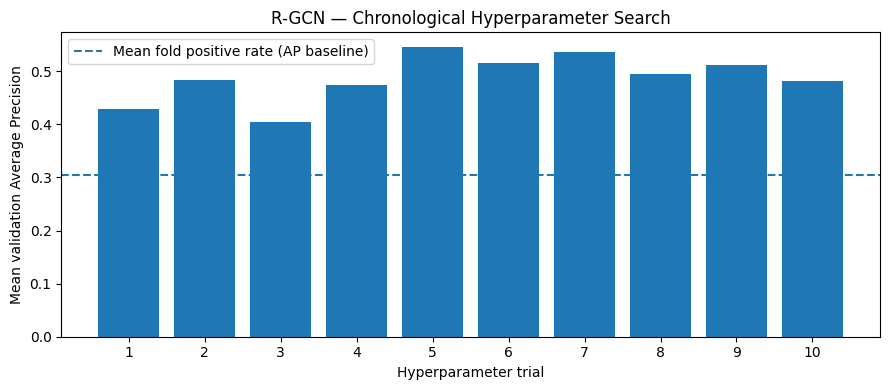

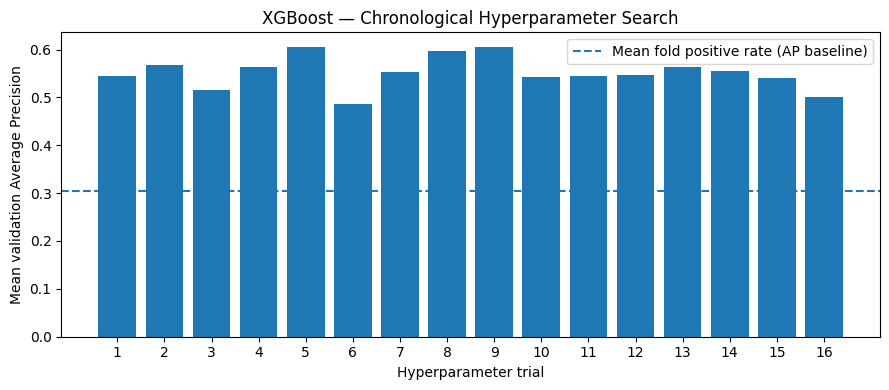

In [28]:
# Visualise development-fold tuning results (not the test set).

for model_name in ["R-GCN", "XGBoost"]:
    data = tuning_summary[
        tuning_summary["model"] == model_name
    ].sort_values("trial")

    plt.figure(figsize=(9, 4))
    plt.bar(data["trial"].astype(str), data["mean_ap"])
    plt.axhline(
        data["mean_baseline_ap"].mean(),
        linestyle="--",
        label="Mean fold positive rate (AP baseline)"
    )

    plt.xlabel("Hyperparameter trial")
    plt.ylabel("Mean validation Average Precision")
    plt.title(f"{model_name} — Chronological Hyperparameter Search")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [29]:
# Use selected architecture, regularisation and training duration. The original train set remains unchanged; tune is diagnostic only here.

torch.manual_seed(TUNING_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TUNING_SEED)

rgcn = RGCNClassifier(
    input_dim=node_x.shape[1],
    hidden_dim=int(best_rgcn_params["hidden_dim"]),
    number_of_relations=len(relation_names),
    dropout=float(best_rgcn_params["dropout"])
).to(device)

optimizer = torch.optim.Adam(
    rgcn.parameters(),
    lr=float(best_rgcn_params["learning_rate"]),
    weight_decay=float(best_rgcn_params["weight_decay"])
)
loss_function = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        class_weight_for_mode(best_rgcn_params["weight_mode"], train_index),
        dtype=torch.float32,
        device=device
    )
)

rgcn_history = []
training_start = time.perf_counter()

for epoch in range(1, rgcn_final_epochs + 1):
    rgcn.train()
    optimizer.zero_grad()
    logits = rgcn(node_x, edge_source, edge_target, edge_relation)
    loss = loss_function(logits[train_nodes], target_tensor[train_nodes])
    loss.backward()
    optimizer.step()

    rgcn.eval()
    with torch.no_grad():
        all_logits = rgcn(node_x, edge_source, edge_target, edge_relation)
        train_probability = torch.sigmoid(all_logits[train_nodes]).cpu().numpy()
        tune_probability = torch.sigmoid(all_logits[tune_nodes]).cpu().numpy()

    rgcn_history.append({
        "epoch": epoch,
        "train_loss": float(loss.item()),
        "train_ap": float(average_precision_score(y[train_index], train_probability)),
        "tune_ap": float(average_precision_score(y[tune_index], tune_probability))
    })

rgcn_training_seconds = time.perf_counter() - training_start
rgcn_history_df = pd.DataFrame(rgcn_history)

torch.save(rgcn.state_dict(), "ss3_rgcn_weights.pt")

print("R-GCN selected trial:", best_rgcn_trial)
print("Final R-GCN epochs:", rgcn_final_epochs)
print("Training time (seconds):", round(rgcn_training_seconds, 2))
display(rgcn_history_df.tail())


R-GCN selected trial: 5
Final R-GCN epochs: 16
Training time (seconds): 0.31


,epoch,train_loss,train_ap,tune_ap
11,12,1.008173,0.438333,0.311887
12,13,0.985768,0.444203,0.312317
13,14,0.991502,0.451366,0.312319
14,15,0.984170,0.463227,0.308495
15,16,0.975336,0.470240,0.306507


### Model 2 — XGBoost

In [30]:
# Use selected parameters and fixed boosting rounds.

xgb = XGBClassifier(
    objective="binary:logistic",
    tree_method="hist",
    n_estimators=xgb_final_rounds,
    max_depth=int(best_xgb_params["max_depth"]),
    min_child_weight=float(best_xgb_params["min_child_weight"]),
    learning_rate=float(best_xgb_params["learning_rate"]),
    reg_alpha=float(best_xgb_params["reg_alpha"]),
    reg_lambda=float(best_xgb_params["reg_lambda"]),
    subsample=float(best_xgb_params["subsample"]),
    colsample_bytree=float(best_xgb_params["colsample_bytree"]),
    scale_pos_weight=class_weight_for_mode(
        best_xgb_params["weight_mode"], train_index
    ),
    eval_metric="logloss",
    n_jobs=4,
    random_state=TUNING_SEED
)

training_start = time.perf_counter()
xgb.fit(
    X[train_index],
    y[train_index],
    eval_set=[
        (X[train_index], y[train_index]),
        (X[tune_index], y[tune_index])
    ],
    verbose=False
)
xgb_training_seconds = time.perf_counter() - training_start

xgb_history = xgb.evals_result()
xgb_training_history = pd.DataFrame({
    "train_logloss": xgb_history["validation_0"]["logloss"],
    "tune_logloss": xgb_history["validation_1"]["logloss"]
})

xgb.save_model("ss3_xgboost.ubj")

print("XGBoost selected trial:", best_xgb_trial)
print("Final XGBoost rounds:", xgb_final_rounds)
print("Training time (seconds):", round(xgb_training_seconds, 2))
display(xgb_training_history.tail())


XGBoost selected trial: 5
Final XGBoost rounds: 233
Training time (seconds): 0.14


,train_logloss,tune_logloss
228,0.557021,0.666914
229,0.556748,0.666752
230,0.556465,0.666540
231,0.556185,0.666391
232,0.556383,0.667092


In [31]:
# R-GCN raw margins.

rgcn.eval()

with torch.no_grad():

    rgcn_margins = (
        rgcn(
            node_x,
            edge_source,
            edge_target,
            edge_relation
        )[:n_movies]
        .cpu()
        .numpy()
    )


# XGBoost raw margins.

xgb_margins = xgb.predict(
    X,
    output_margin=True
)


from scipy.special import expit

rgcn_probability = expit(rgcn_margins)
xgb_probability = expit(xgb_margins)

## Model Validation

Primary Evaluation Metric: Average Precision
Secondary Evaluation Metrics: ROC_AUC

In [32]:
# Define Precision@K and Lift@K


def ranking_metrics_at_k(y_true, probabilities, k):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    # Rank titles from highest to lowest predicted probability.
    ranked_indices = np.argsort(
        -probabilities,
        kind="stable"
    )

    top_k = ranked_indices[:k]

    # Proportion of successful titles in the top K.
    precision_k = y_true[top_k].mean()

    # Success rate across the entire evaluation population.
    baseline_rate = y_true.mean()

    # Improvement over random selection.
    lift_k = (
        precision_k / baseline_rate
        if baseline_rate > 0
        else np.nan
    )

    return float(precision_k), float(lift_k)



# Define model probabilities

baseline_probability = np.full(
    len(titles),
    y[train_index].mean()
)

model_probabilities = {
    "R-GCN": rgcn_probability,
    "XGBoost": xgb_probability,
    "Baseline": baseline_probability
}



# Evaluate training and test performance

metric_rows = []

for split_name, row_index in {
    "Train": train_index,
    "Test": test_index
}.items():

    y_true = y[row_index]
    positive_rate = y_true.mean()

    assert len(y_true) >= 10, (
        f"{split_name} requires at least 10 titles."
    )

    for model_name, all_probabilities in model_probabilities.items():

        probabilities = np.asarray(
            all_probabilities[row_index]
        )

        # Average Precision and ROC-AUC.
        ap = average_precision_score(
            y_true,
            probabilities
        )

        auc = (
            roc_auc_score(y_true, probabilities)
            if len(np.unique(y_true)) == 2
            else np.nan
        )

        # A constant baseline has no meaningful ranking.
        # Use expected random-selection performance.
        if model_name == "Baseline":

            p5 = positive_rate
            p10 = positive_rate

            lift5 = 1.0
            lift10 = 1.0

        else:

            p5, lift5 = ranking_metrics_at_k(
                y_true,
                probabilities,
                k=5
            )

            p10, lift10 = ranking_metrics_at_k(
                y_true,
                probabilities,
                k=10
            )

        metric_rows.append({
            "split": split_name,
            "model": model_name,
            "titles": len(row_index),
            "positive_rate": positive_rate,
            "average_precision": ap,
            "roc_auc": auc,
            "precision_at_5": p5,
            "precision_at_10": p10,
            "lift_at_5": lift5,
            "lift_at_10": lift10
        })



# Display evaluation results

model_metrics = pd.DataFrame(metric_rows)

display(model_metrics.round(4))

,split,model,titles,positive_rate,average_precision,roc_auc,precision_at_5,precision_at_10,lift_at_5,lift_at_10
0,Train,R-GCN,273,0.2674,0.4702,0.7097,0.6000,0.5000,2.2438,1.8699
1,Train,XGBoost,273,0.2674,0.7685,0.8725,1.0000,1.0000,3.7397,3.7397
2,Train,Baseline,273,0.2674,0.2674,0.5000,0.2674,0.2674,1.0000,1.0000
3,Test,R-GCN,68,0.2647,0.3234,0.5644,0.4000,0.3000,1.5111,1.1333
4,Test,XGBoost,68,0.2647,0.4064,0.6244,0.4000,0.4000,1.5111,1.5111
5,Test,Baseline,68,0.2647,0.2647,0.5000,0.2647,0.2647,1.0000,1.0000


### Model Comparison Testing

In [33]:
bootstrap_rng = np.random.default_rng(42)

test_target = y[test_index]
rgcn_test = rgcn_probability[test_index]
xgb_test = xgb_probability[test_index]

ap_differences = []

for _ in range(1000):

    sample = bootstrap_rng.integers(
        0,
        len(test_target),
        len(test_target)
    )

    sampled_target = test_target[sample]

    if np.unique(sampled_target).size < 2:
        continue

    rgcn_ap = average_precision_score(
        sampled_target,
        rgcn_test[sample]
    )

    xgb_ap = average_precision_score(
        sampled_target,
        xgb_test[sample]
    )

    ap_differences.append(xgb_ap - rgcn_ap)


ap_difference = (
    average_precision_score(test_target, xgb_test)
    - average_precision_score(test_target, rgcn_test)
)

ci_lower, ci_upper = np.percentile(
    ap_differences,
    [2.5, 97.5]
)

comparison_summary = pd.DataFrame({
    "comparison": ["XGBoost AP - R-GCN AP"],
    "observed_difference": [ap_difference],
    "ci_95_lower": [ci_lower],
    "ci_95_upper": [ci_upper]
})

display(comparison_summary)

,comparison,observed_difference,ci_95_lower,ci_95_upper
0,XGBoost AP - R-GCN AP,0.083,-0.114739,0.266258


### Model Predicitons

In [34]:
title_predictions = titles[
    [
        "title_id",
        "title_name",
        "acquisition_date",
        "role",
        "target"
    ]
].copy()

title_predictions["rgcn_probability"] = rgcn_probability
title_predictions["xgboost_probability"] = xgb_probability

title_predictions.to_csv(
    "ss3_title_predictions.csv",
    index=False
)


# Score recent, unlabelled titles whose six-month outcome
# is not yet fully observable.

recent_cutoff = (
    log_end - pd.DateOffset(months=OBSERVATION_MONTHS)
)

recent_titles = title_predictions[
    (title_predictions["role"] == "unlabelled")
    & (
        title_predictions["acquisition_date"]
        > recent_cutoff
    )
].copy()

display(
    recent_titles.sort_values(
        "xgboost_probability",
        ascending=False
    ).head(15)
)

,title_id,title_name,acquisition_date,role,target,rgcn_probability,xgboost_probability
218,stad-liv-1838,Champions League 2026,2026-03-14,unlabelled,-1,0.404185,0.669767
927,stad-ser-1636,The Promise II,2026-08-25,unlabelled,-1,0.415263,0.626856
47,stad-doc-1435,Midnight Reckoning,2026-03-10,unlabelled,-1,0.416925,0.613866
1000,stad-ser-1867,Red Kingdom Chronicles,2026-04-26,unlabelled,-1,0.389708,0.609348
93,stad-doc-1884,Northern Storm 3,2026-07-10,unlabelled,-1,0.397439,0.607418
20,stad-doc-1201,Midnight Highveld,2026-03-12,unlabelled,-1,0.340137,0.604803
163,stad-liv-1429,Golf Open Championship 2023,2026-08-02,unlabelled,-1,0.502616,0.604511
220,stad-liv-1849,Second Mountain 2,2026-07-08,unlabelled,-1,0.481814,0.602355
423,stad-mov-1426,Long Harvest III,2026-05-12,unlabelled,-1,0.443464,0.594004
1068,stad-ser-2067,Bitter Kingdom,2026-06-16,unlabelled,-1,0.329435,0.593236
